# Paper 3 — Controlled second-seed β-VAE experiment
Train **β=4, seed=42, 30,000 steps**, without touching the original seed-2026 checkpoints. Assumes you already ran the original notebook's setup/data cells in the **same Colab runtime**. If runtime was reset, rerun its clone/Drive setup cells before this notebook. Uses the existing checked-in `src.train` and `src.visualize` unchanged. The original β=1 checkpoint is used only as the reference for Figure 7B.

In [ ]:

from google.colab import drive, userdata
from pathlib import Path
import os, subprocess, tempfile

drive.mount('/content/drive')

REPO = Path('/content/advanced-ml-paper-reproductions')
PROJECT = REPO / 'paper3-beta-vae'

token = userdata.get('GITHUB_TOKEN')
assert token, "Add GITHUB_TOKEN to Colab Secrets."

with tempfile.TemporaryDirectory() as tmp:
    askpass = Path(tmp) / 'askpass.sh'
    askpass.write_text(
        '#!/bin/sh\n'
        'case "$1" in\n'
        '  *Username*) printf "x-access-token" ;;\n'
        '  *Password*) printf "%s" "$GITHUB_TOKEN" ;;\n'
        'esac\n'
    )
    askpass.chmod(0o700)

    env = dict(
        os.environ,
        GITHUB_TOKEN=token,
        GIT_ASKPASS=str(askpass),
        GIT_TERMINAL_PROMPT='0'
    )

    if (REPO / '.git').is_dir():
        print('Pulling latest repository changes...')
        subprocess.run(
            ['git', 'pull', '--ff-only'],
            cwd=REPO, env=env, check=True
        )
    elif not REPO.exists():
        print('Cloning repository...')
        subprocess.run(
            [
                'git', 'clone', '--quiet',
                'https://github.com/vepaan/advanced-ml-paper-reproductions.git',
                str(REPO)
            ],
            env=env, check=True
        )
    else:
        raise RuntimeError(f'Unexpected directory at {REPO}')

del token

%cd /content/advanced-ml-paper-reproductions/paper3-beta-vae

assert (PROJECT / 'src/train.py').is_file()
assert (PROJECT / 'src/visualize.py').is_file()

print('Repository ready!')


Mounted at /content/drive
Cloning repository...
/content/advanced-ml-paper-reproductions/paper3-beta-vae
Repository ready!


In [ ]:

import shutil
from pathlib import Path

DRIVE_RUNS = Path('/content/drive/MyDrive/ML-Paper-Reproductions/paper3')
ORIGINAL = Path('/content/paper3_runs')

for beta in (1, 4):
    source = DRIVE_RUNS / f'beta{beta}' / 'model.pt'
    target = ORIGINAL / f'beta{beta}' / 'model.pt'

    assert source.is_file(), f'Missing backup: {source}'

    target.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, target)

    print(f'Restored beta={beta}: {target}')


Restored beta=1: /content/paper3_runs/beta1/model.pt
Restored beta=4: /content/paper3_runs/beta4/model.pt


In [ ]:
from pathlib import Path
import torch, sys
PROJECT = Path('/content/advanced-ml-paper-reproductions/paper3-beta-vae')
DATA = PROJECT / 'data/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz'
ORIGINAL = Path('/content/paper3_runs')
SECOND = Path('/content/paper3_seed42')
BACKUP = Path('/content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed42')
FIGURES = Path('/content/paper3_figure7_seed42')
for p in (PROJECT/'src/train.py',PROJECT/'src/visualize.py',DATA,ORIGINAL/'beta1/model.pt'):
    assert p.is_file(), f'Missing {p}. Run original Colab setup first.'
assert torch.cuda.is_available(), 'Select a GPU runtime.'
SECOND.mkdir(parents=True,exist_ok=True)
FIGURES.mkdir(parents=True,exist_ok=True)
print('GPU:', torch.cuda.get_device_name(0))
print('New beta4 run:', SECOND/'beta4')
print('Original beta1 reference:', ORIGINAL/'beta1/model.pt')
%cd /content/advanced-ml-paper-reproductions/paper3-beta-vae

GPU: Tesla T4
New beta4 run: /content/paper3_seed42/beta4
Original beta1 reference: /content/paper3_runs/beta1/model.pt
/content/advanced-ml-paper-reproductions/paper3-beta-vae


## Train or resume new β=4 seed=42
Uses a new output root and a new Drive backup directory. `--max-steps 30000` means total steps, **not** 30,000 additional steps if resumed. Expected T4 training is several minutes. Watch for `NEW run beta4: seed 42`; if this is a resumed experiment, expect `RESUMED` with the correct seed.

In [ ]:
MAX_STEPS = 30000
!{sys.executable} -u -m src.train --beta 4 --data "{DATA}" --output-root "{SECOND}" --backup-root "{BACKUP}" --max-steps {MAX_STEPS} --batch-size 256 --learning-rate 0.01 --seed 42 --ckpt-every 2000 --log-every 500

NEW run beta4: seed 42, Adagrad lr=0.01; identical initialization across beta arms when seeds match
Parameters=14,196,516; samples=737,280; batch=256; requested_steps=30000; device=cuda
{"step": 500, "epoch": 0.1736, "loss": 538.98407, "recon": 368.0611, "kl": 42.73085, "elapsed_sec": 4.8}
{"step": 1000, "epoch": 0.3472, "loss": 198.99683, "recon": 162.02635, "kl": 9.2426, "elapsed_sec": 8.6}
{"step": 1500, "epoch": 0.5208, "loss": 164.28207, "recon": 129.22124, "kl": 8.76521, "elapsed_sec": 12.5}
{"step": 2000, "epoch": 0.6944, "loss": 154.33847, "recon": 120.57987, "kl": 8.43968, "elapsed_sec": 16.5}
SAVED step=2000: /content/paper3_seed42/beta4/latest.pt
{"step": 2500, "epoch": 0.8681, "loss": 149.97717, "recon": 116.30199, "kl": 8.41883, "elapsed_sec": 22.0}
{"step": 3000, "epoch": 1.0417, "loss": 147.72043, "recon": 113.90425, "kl": 8.45405, "elapsed_sec": 26.0}
{"step": 3500, "epoch": 1.2153, "loss": 146.40103, "recon": 112.50991, "kl": 8.47277, "elapsed_sec": 30.0}
{"step": 4000

## Verify checkpoints and stage only inference weights
The original β=1 and β=4 runs are **never overwritten**. Copy seed-42 β=4 inference weights plus original β=1 inference weights into a separate comparison directory. Do not copy `latest.pt`, because no training happens in this comparison directory.

In [ ]:
import shutil
STAGED = Path('/content/paper3_seed42_comparison')
for beta, source in ((1,ORIGINAL/'beta1/model.pt'),(4,SECOND/'beta4/model.pt')):
    assert source.is_file(), f'Missing {source}'
    state=torch.load(source,map_location='cpu',weights_only=False)
    expected_seed=2026 if beta==1 else 42
    assert state['beta']==beta and state['seed']==expected_seed and state['step']==MAX_STEPS, (beta,state['seed'],state['step'])
    destination=STAGED/f'beta{beta}/model.pt'
    destination.parent.mkdir(parents=True,exist_ok=True)
    shutil.copy2(source,destination)
    print(f'β={beta}: seed={state["seed"]}, steps={state["step"]} -> {destination}')

β=1: seed=2026, steps=30000 -> /content/paper3_seed42_comparison/beta1/model.pt
β=4: seed=42, steps=30000 -> /content/paper3_seed42_comparison/beta4/model.pt


## Regenerate A (β=4, seed=42) and B (β=1, seed=2026)
These are **not same-seed controlled β comparisons**. Panel B is the stable β=1 reference for judging whether the second β=4 initialization differs from the earlier β=4, seed=2026 result. Clearly label this pairing in your report.

In [ ]:
!{sys.executable} -u -m src.visualize --panel both --data "{DATA}" --output-root "{STAGED}" --figures-dir "{FIGURES}" --device auto --eval-batch-size 2048

Figure 7A ready {"step": 30000, "latents": [9, 6, 3, 8, 10, 5], "kl": [0.0004, 0.0004, 2.6755, 0.0004, 0.0007, 2.8038, 0.0003, 0.915, 3.1847, 0.0003]}
Figure 7B ready {"step": 30000, "latents": [6, 8, 4, 3, 9, 1], "kl": [0.0103, 0.1113, 2.6798, 3.5377, 0.1591, 3.7477, 0.0464, 3.5463, 1.8469, 0.0108]}
Plot limits (same for BOTH beta arms): {"position_mean": 3.0637785403264894, "scale_mean": 1.4068034548805373, "rotation_mean": 2.0740510697626933}
Output: /content/paper3_figure7_seed42


β=4 seed 42 vs β=1 seed 2026 (reference only)


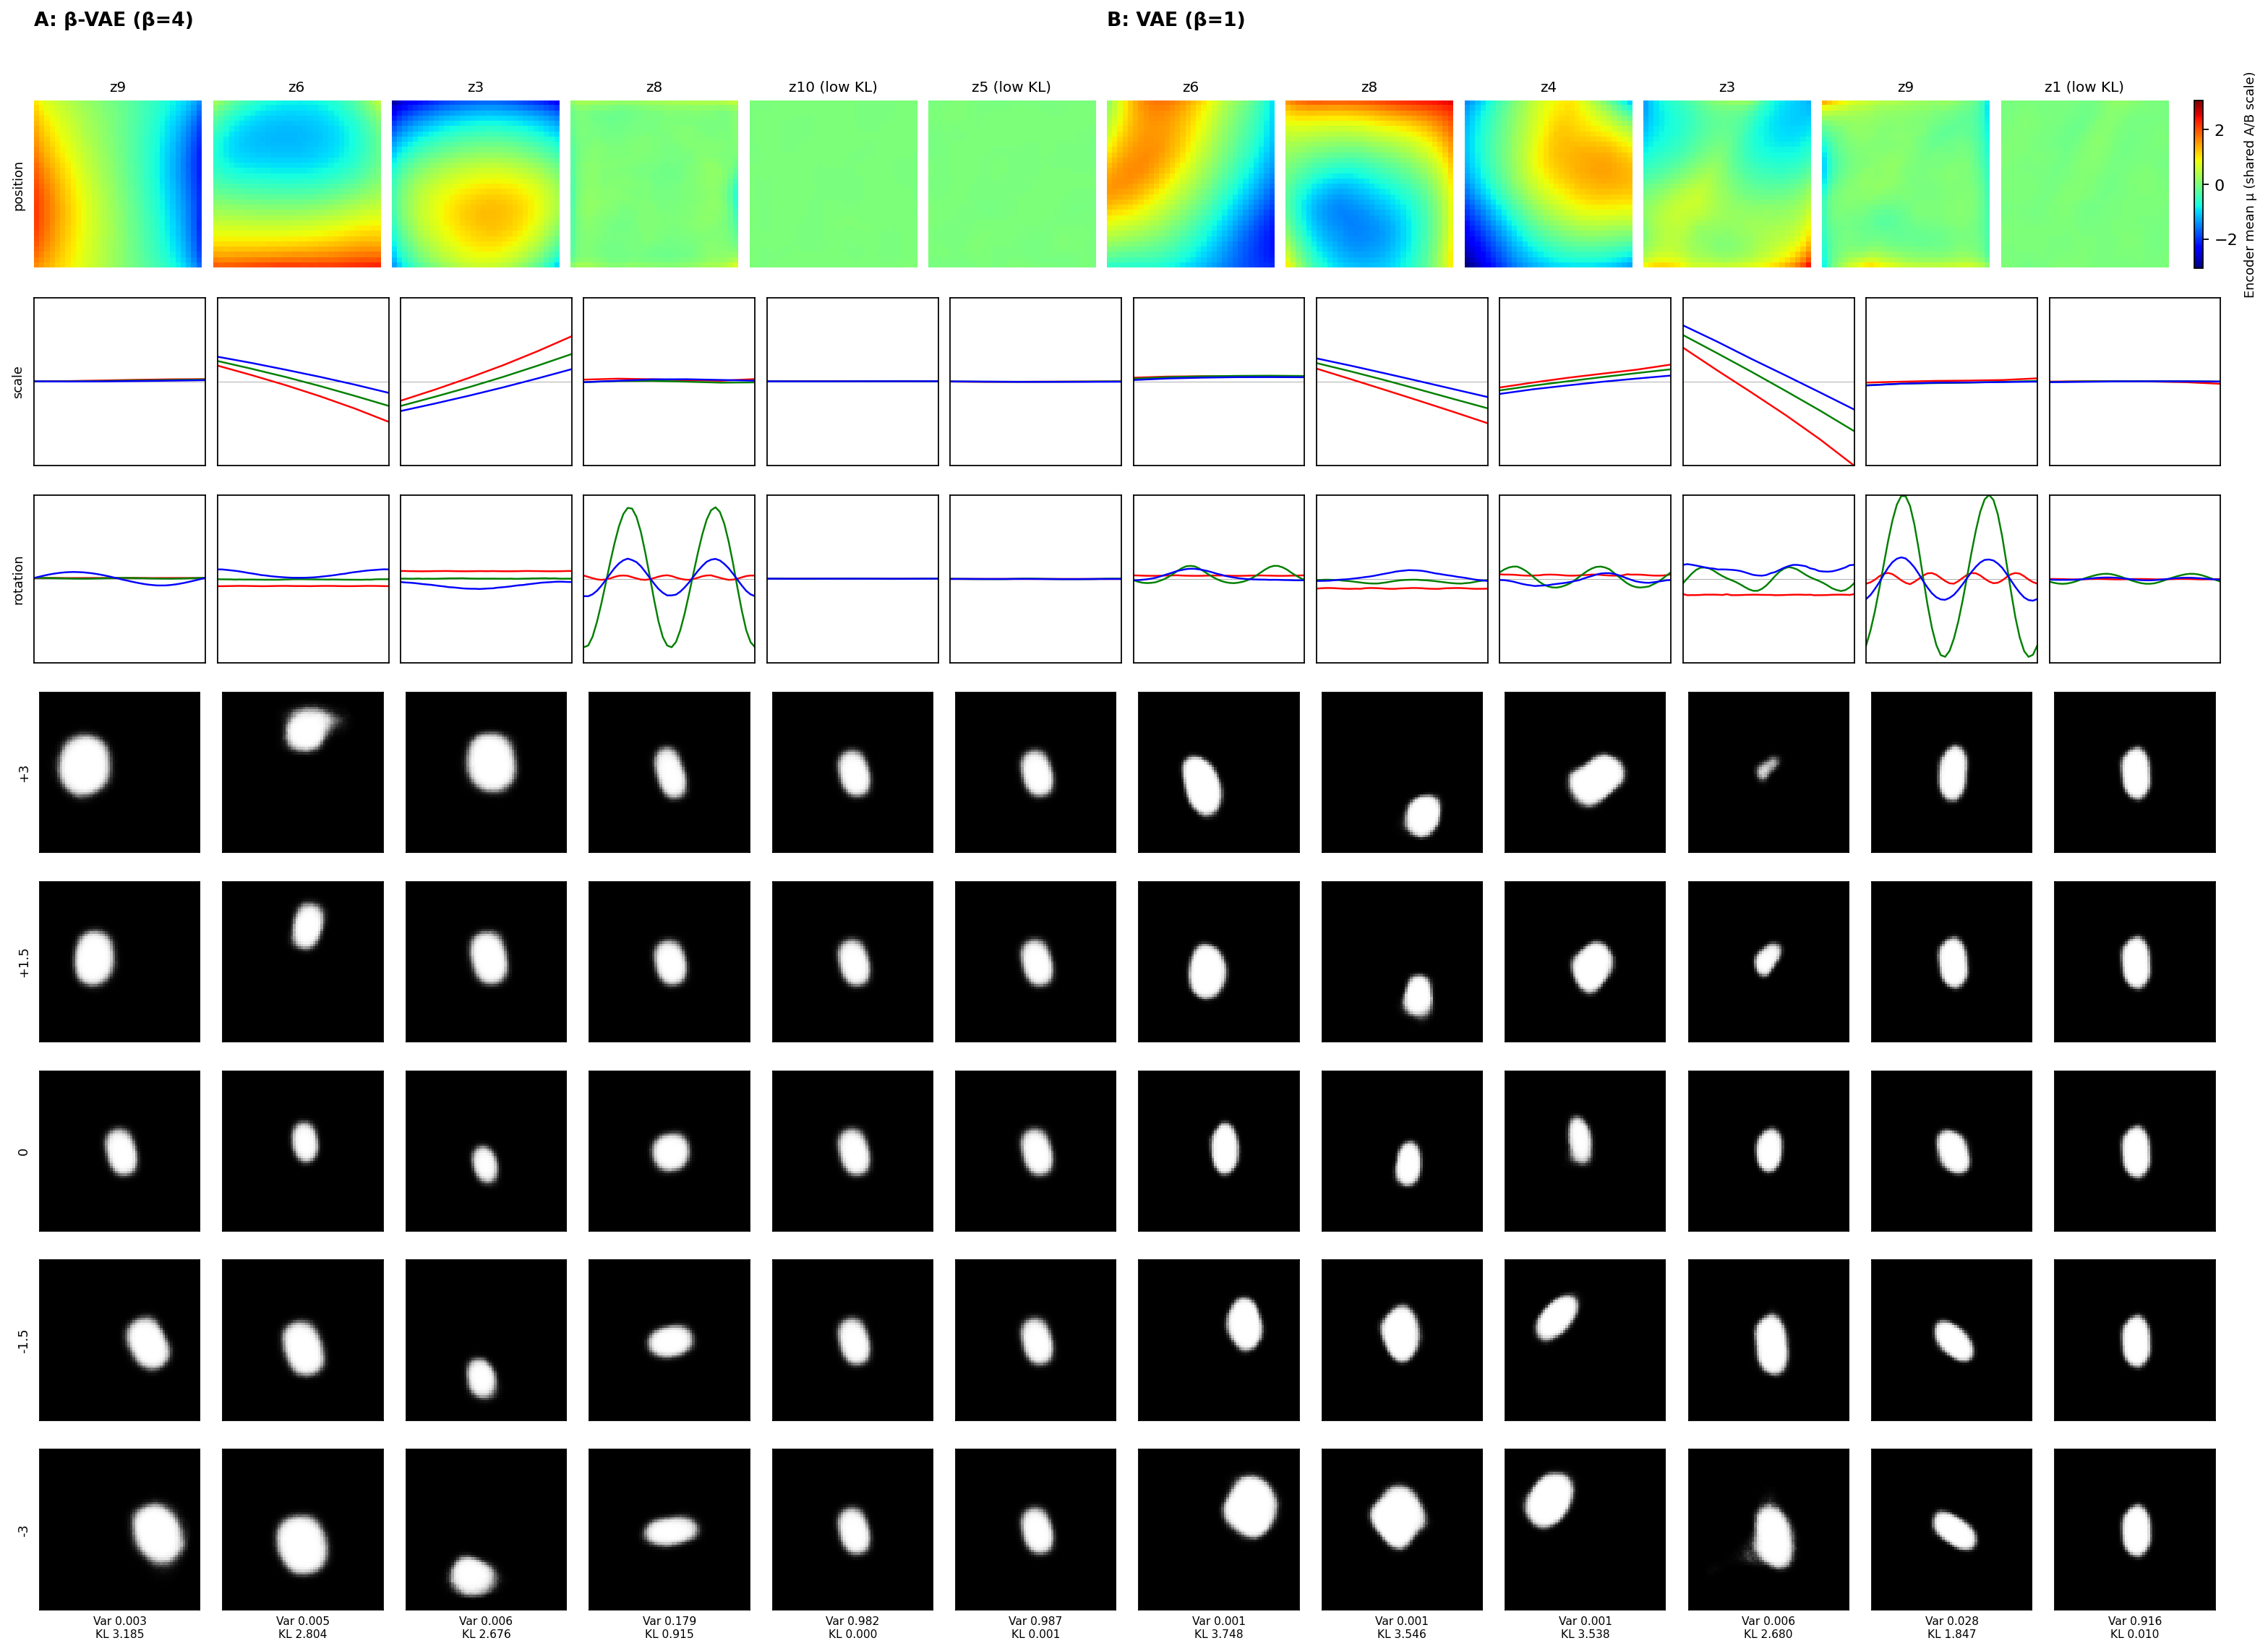


Panel A: beta=4.0 seed=42 steps=30000
displayed latents: [9, 6, 3, 8, 10, 5]
KL by latent: [0.0004, 0.0004, 2.6755, 0.0004, 0.0007, 2.8038, 0.0003, 0.915, 3.1847, 0.0003]
reconstruction: {'n_images': 2048, 'bce_per_image': 86.06331443786621, 'kl_per_image': 9.598229169845581, 'pixel_accuracy': 0.9907044172286987, 'note': 'Reconstruction at deterministic posterior mean; descriptive subset of training distribution.'}
  z9: {'position_x': 0.981, 'position_y': 0.014, 'scale': 0.0, 'rotation': 0.005}
  z6: {'position_x': 0.039, 'position_y': 0.882, 'scale': 0.077, 'rotation': 0.002}
  z3: {'position_x': 0.164, 'position_y': 0.728, 'scale': 0.107, 'rotation': 0.001}
  z8: {'position_x': 0.006, 'position_y': 0.007, 'scale': 0.0, 'rotation': 0.987}
  z10: {'position_x': 0.295, 'position_y': 0.511, 'scale': 0.045, 'rotation': 0.149}
  z5: {'position_x': 0.245, 'position_y': 0.547, 'scale': 0.097, 'rotation': 0.111}

Panel B: beta=1.0 seed=2026 steps=30000
displayed latents: [6, 8, 4, 3, 9, 1]


In [ ]:
import json
from IPython.display import display, Image
print('β=4 seed 42 vs β=1 seed 2026 (reference only)')
display(Image(filename=str(FIGURES/'figure7_AB.png')))
with open(FIGURES/'figure7_metrics.json') as f:
    metrics=json.load(f)
for label in ('A','B'):
    m=metrics[label]
    print(f'\nPanel {label}: beta={m["beta"]} seed={m["seed"]} steps={m["steps"]}')
    print('displayed latents:',m['displayed_latent_ids_1_based'])
    print('KL by latent:',[round(v,4) for v in m['mean_kl_all_10']])
    print('reconstruction:',m['reconstruction'])
    diagnostic=m.get('factor_response_diagnostics',{})
    fractions=diagnostic.get('within_4_factor_signal_fractions',{})
    for lat in m['displayed_latent_ids_1_based']:
        j=lat-1
        print(f'  z{lat}:', {key:round(values[j],3) for key,values in fractions.items()})

In [ ]:

from pathlib import Path
import torch, shutil, json, hashlib, sys

PROJECT = Path('/content/advanced-ml-paper-reproductions/paper3-beta-vae')
DATA = PROJECT / 'data/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz'

ORIGINAL = Path('/content/paper3_runs')
SECOND = Path('/content/paper3_seed42')
THIRD = Path('/content/paper3_seed123')

DRIVE_BASE = Path('/content/drive/MyDrive/ML-Paper-Reproductions')
ARCHIVE = DRIVE_BASE / 'paper3_seed_comparison'

assert (PROJECT / 'src/train.py').is_file()
assert (PROJECT / 'src/visualize.py').is_file()
assert DATA.is_file()
assert torch.cuda.is_available()

ARCHIVE.mkdir(parents=True, exist_ok=True)

def preserve(src, dst):
    assert src.is_file(), f'Missing source: {src}'
    dst.parent.mkdir(parents=True, exist_ok=True)
    if dst.exists():
        def digest(p):
            h = hashlib.sha256()
            with p.open('rb') as f:
                for chunk in iter(lambda: f.read(4 * 1024 * 1024), b''):
                    h.update(chunk)
            return h.hexdigest()
        assert digest(src) == digest(dst), f'Archive conflict: {dst}'
        print('Already archived:', dst)
    else:
        shutil.copy2(src, dst)
        print('Preserved:', dst)

runs = [
    ('beta1_seed2026', ORIGINAL / 'beta1', 1, 2026),
    ('beta4_seed2026', ORIGINAL / 'beta4', 4, 2026),
    ('beta4_seed42', SECOND / 'beta4', 4, 42),
]

for name, run, beta, seed in runs:
    # Restore the inference checkpoint from Drive if needed.
    if not (run / 'model.pt').is_file():
        backup_root = (DRIVE_BASE / 'paper3'
                       if seed == 2026 else DRIVE_BASE / 'paper3_seed42')
        source = backup_root / f'beta{beta}' / 'model.pt'
        assert source.is_file(), f'Missing checkpoint: {source}'
        run.mkdir(parents=True, exist_ok=True)
        shutil.copy2(source, run / 'model.pt')

    ckpt = torch.load(run / 'model.pt',
                      map_location='cpu', weights_only=False)
    assert ckpt['beta'] == beta
    assert ckpt['seed'] == seed
    assert ckpt['step'] == 30000

    dest = ARCHIVE / name
    preserve(run / 'model.pt', dest / 'model.pt')

    # Preserve resumable state if available.
    for filename in ('latest.pt', 'history.json'):
        source = run / filename
        if source.exists():
            preserve(source, dest / filename)

# Preserve previously generated figures when present.
figure_dirs = {
    'seed2026': Path('/content/paper3_figure7_30000'),
    'seed42': Path('/content/paper3_figure7_seed42'),
}

for label, folder in figure_dirs.items():
    if folder.is_dir():
        for file in folder.glob('figure7_*'):
            if file.is_file():
                preserve(file, ARCHIVE / label / file.name)

print('\nOriginal checkpoints verified and archived.')
print('Archive:', ARCHIVE)

%cd /content/advanced-ml-paper-reproductions/paper3-beta-vae


Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/beta1_seed2026/model.pt
Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/beta4_seed2026/model.pt
Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/beta4_seed42/model.pt
Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/beta4_seed42/latest.pt
Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/beta4_seed42/history.json
Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/seed42/figure7_B.png
Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/seed42/figure7_AB.png
Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/seed42/figure7_metrics.json
Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/seed42/figure7_A.png

Original checkpoints verified and archived.
Archive: /content/drive/

In [ ]:

MAX_STEPS = 30000
BATCH_SIZE = 256
SEED = 123

THIRD_BACKUP = DRIVE_BASE / 'paper3_seed123'

print('Starting beta=4, seed=123')
print('Output:', THIRD)
print('Drive backup:', THIRD_BACKUP)

!{sys.executable} -u -m src.train --beta 4 --data "{DATA}" --output-root "{THIRD}" --backup-root "{THIRD_BACKUP}" --max-steps {MAX_STEPS} --batch-size {BATCH_SIZE} --learning-rate 0.01 --seed {SEED} --ckpt-every 2000 --log-every 500


Starting beta=4, seed=123
Output: /content/paper3_seed123
Drive backup: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed123
NEW run beta4: seed 123, Adagrad lr=0.01; identical initialization across beta arms when seeds match
Parameters=14,196,516; samples=737,280; batch=256; requested_steps=30000; device=cuda
{"step": 500, "epoch": 0.1736, "loss": 695.66632, "recon": 519.53076, "kl": 44.0339, "elapsed_sec": 4.5}
{"step": 1000, "epoch": 0.3472, "loss": 226.1328, "recon": 181.77719, "kl": 11.08889, "elapsed_sec": 8.4}
{"step": 1500, "epoch": 0.5208, "loss": 177.88493, "recon": 135.91254, "kl": 10.49306, "elapsed_sec": 12.3}
{"step": 2000, "epoch": 0.6944, "loss": 164.07275, "recon": 124.98214, "kl": 9.77266, "elapsed_sec": 16.3}
SAVED step=2000: /content/paper3_seed123/beta4/latest.pt
{"step": 2500, "epoch": 0.8681, "loss": 157.15979, "recon": 119.56977, "kl": 9.3975, "elapsed_sec": 21.9}
{"step": 3000, "epoch": 1.0417, "loss": 153.51331, "recon": 116.39613, "kl": 9.2793, "elaps

In [ ]:

THIRD_MODEL = THIRD / 'beta4/model.pt'

assert THIRD_MODEL.is_file(), 'Seed 123 training did not finish.'

ckpt = torch.load(
    THIRD_MODEL,
    map_location='cpu',
    weights_only=False
)

assert ckpt['beta'] == 4
assert ckpt['seed'] == 123
assert ckpt['step'] == 30000

dest = ARCHIVE / 'beta4_seed123'

for filename in ('model.pt', 'latest.pt', 'history.json'):
    source = THIRD / 'beta4' / filename
    if source.is_file():
        preserve(source, dest / filename)

print('Seed 123 confirmed:')
print('beta:', ckpt['beta'])
print('seed:', ckpt['seed'])
print('steps:', ckpt['step'])
print('All three β=4 experiments preserved.')


Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/beta4_seed123/model.pt
Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/beta4_seed123/latest.pt
Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/beta4_seed123/history.json
Seed 123 confirmed:
beta: 4.0
seed: 123
steps: 30000
All three β=4 experiments preserved.


In [ ]:

from IPython.display import display, Image

FIGURE_ROOT = Path('/content/paper3_three_seeds')
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)

seed_runs = {
    2026: ORIGINAL,
    42: SECOND,
    123: THIRD
}

for seed, run_root in seed_runs.items():
    ckpt_path = run_root / 'beta4/model.pt'
    assert ckpt_path.is_file(), f'Missing {ckpt_path}'

    output = FIGURE_ROOT / f'seed{seed}'
    output.mkdir(parents=True, exist_ok=True)

    print(f'\nGenerating Figure 7A for seed {seed}...', flush=True)

    # Execute unbuffered and display evaluation output directly.
    result = subprocess.run(
        [
            sys.executable, '-u', '-m', 'src.visualize',
            '--panel', 'A',
            '--data', str(DATA),
            '--output-root', str(run_root),
            '--figures-dir', str(output),
            '--device', 'auto',
            '--eval-batch-size', '2048'
        ],
        cwd=PROJECT,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True
    )

    if result.returncode != 0:
        print(result.stdout[-8000:])
        raise RuntimeError(f'Visualization failed for seed {seed}')

    assert (output / 'figure7_A.png').is_file()
    assert (output / 'figure7_metrics.json').is_file()

    # Persist images and numerical evaluation.
    for filename in ('figure7_A.png', 'figure7_metrics.json'):
        preserve(output / filename,
                 ARCHIVE / f'seed{seed}_recomputed' / filename)

    print(f'Seed {seed} completed.')

print('\nAll three Figure 7A panels generated.')



Generating Figure 7A for seed 2026...
Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/seed2026_recomputed/figure7_A.png
Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/seed2026_recomputed/figure7_metrics.json
Seed 2026 completed.

Generating Figure 7A for seed 42...
Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/seed42_recomputed/figure7_A.png
Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/seed42_recomputed/figure7_metrics.json
Seed 42 completed.

Generating Figure 7A for seed 123...
Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/seed123_recomputed/figure7_A.png
Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/seed123_recomputed/figure7_metrics.json
Seed 123 completed.

All three Figure 7A panels generated.


THREE-SEED SUMMARY


,Seed,Steps,Active latents (KL > 0.1),Total KL,BCE / image,Best X response,Best Y response,Best scale response,Best rotation response
0,2026,30000,4,9.971,85.061,0.730,0.553,0.387,0.407
1,42,30000,4,9.581,86.063,0.981,0.882,0.663,0.987
2,123,30000,4,9.681,85.828,0.690,0.747,0.324,0.573



ACTIVE LATENT DIAGNOSTICS


,Seed,Latent,KL,X,Y,Scale,Rotation
3,2026,z4,2.1688,0.730,0.156,0.057,0.057
4,2026,z5,2.8496,0.475,0.518,0.004,0.003
5,2026,z6,2.9325,0.536,0.460,0.000,0.003
9,2026,z10,2.0165,0.036,0.553,0.387,0.023
12,42,z3,2.6755,0.164,0.728,0.107,0.001
15,42,z6,2.8038,0.039,0.882,0.077,0.002
17,42,z8,0.9150,0.006,0.007,0.000,0.987
18,42,z9,3.1847,0.981,0.014,0.000,0.005
20,123,z1,1.2801,0.117,0.209,0.223,0.451
22,123,z3,2.5444,0.472,0.449,0.075,0.005


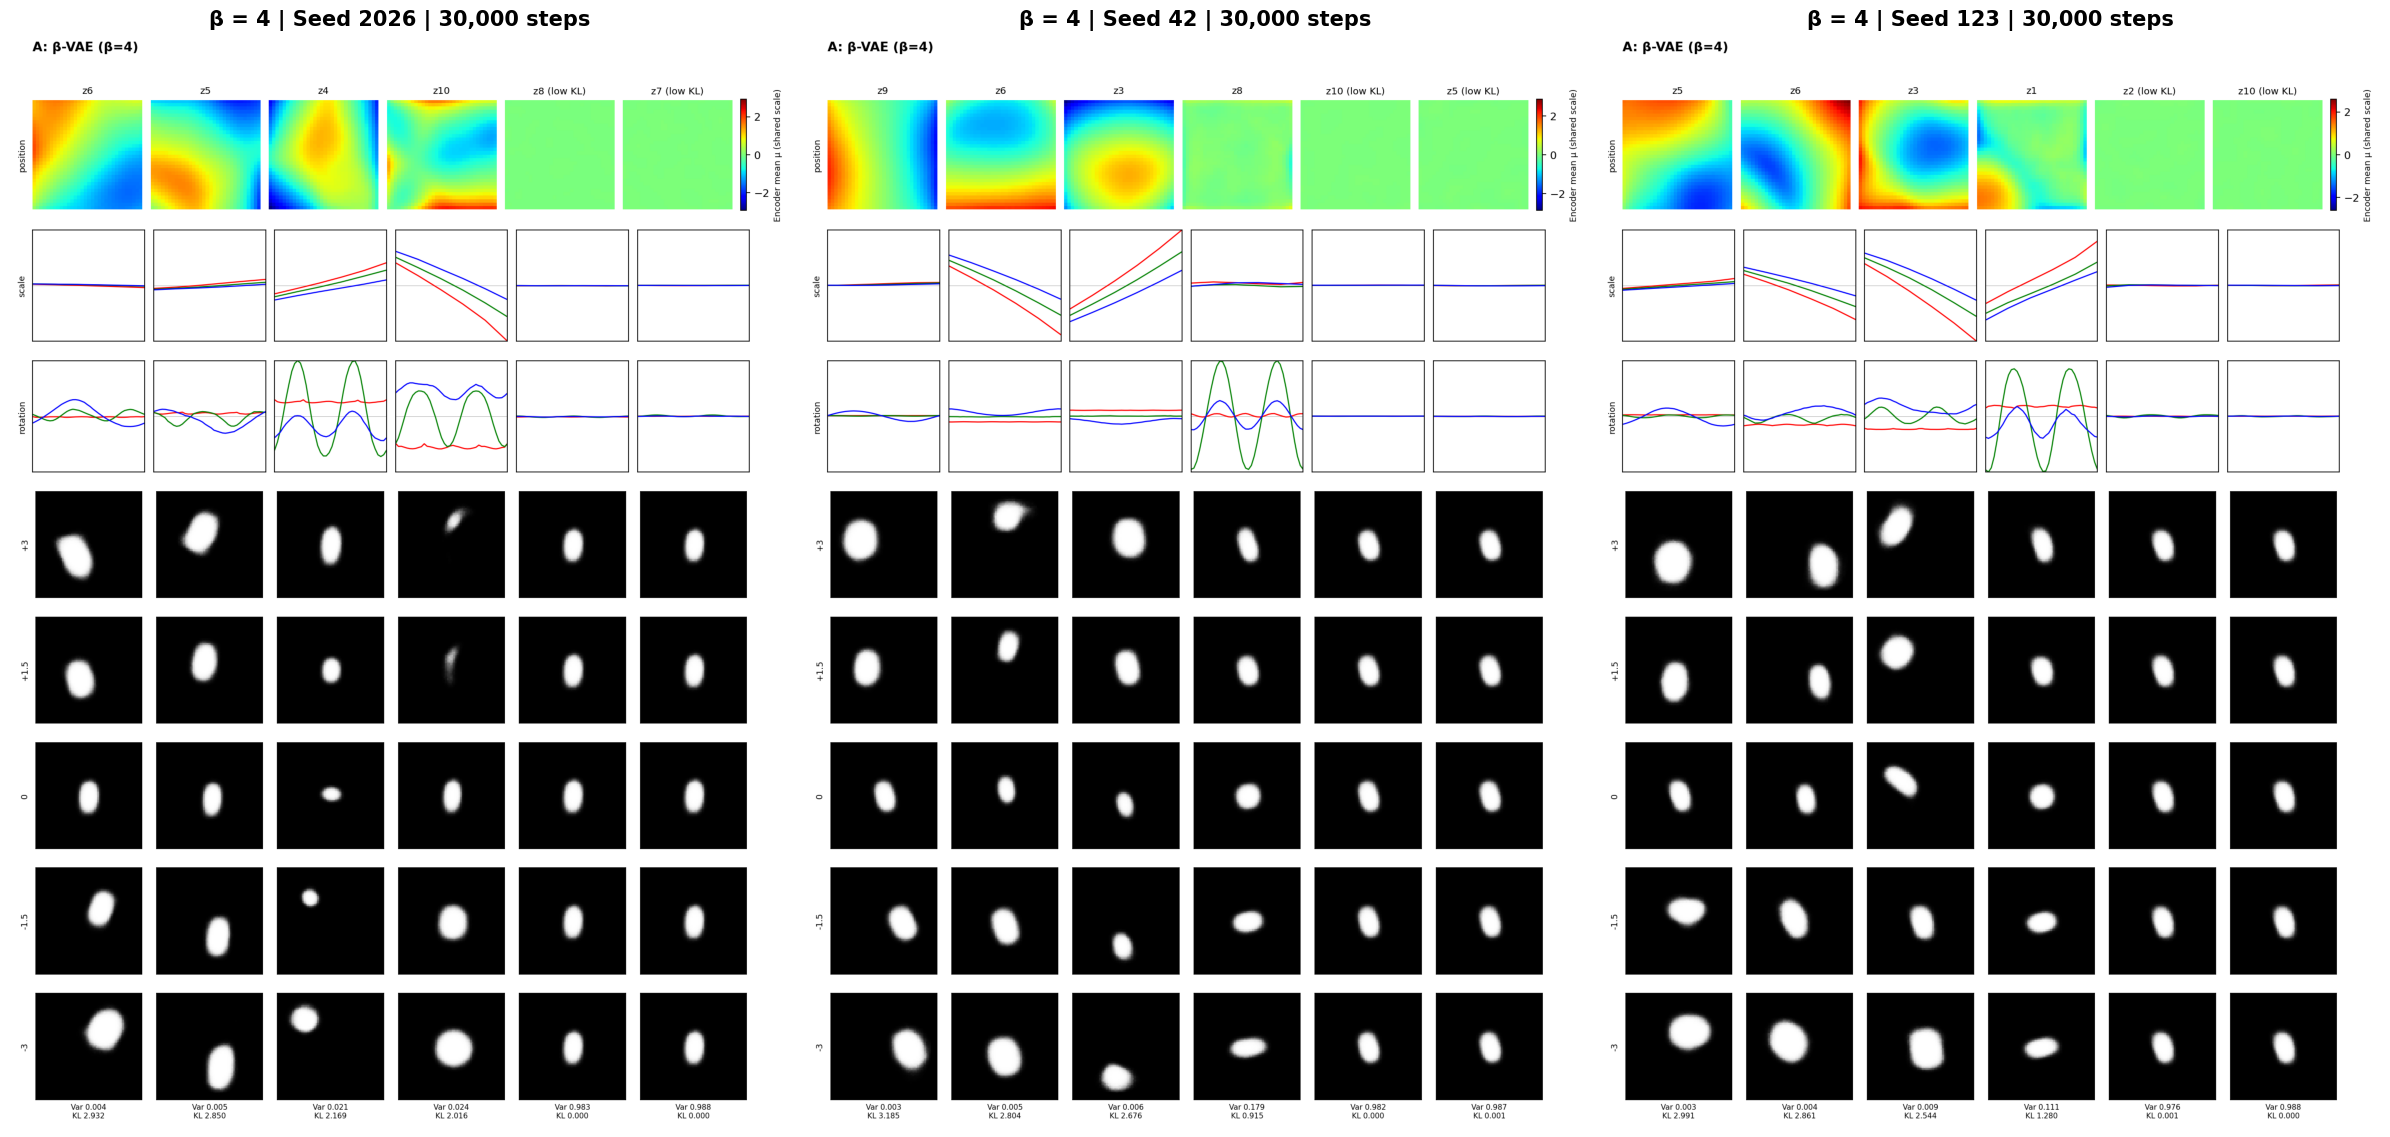

Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/comparison/three_seed_comparison.png
Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/comparison/seed_summary.csv
Preserved: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/comparison/latent_diagnostics.csv

Comparison saved: /content/paper3_three_seeds/three_seed_comparison.png
Persistent archive: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison


In [ ]:

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from IPython.display import display

summaries = []
latent_rows = []
images = []

for seed in (2026, 42, 123):
    folder = FIGURE_ROOT / f'seed{seed}'

    with open(folder / 'figure7_metrics.json') as f:
        m = json.load(f)['A']

    assert int(m['seed']) == seed
    assert int(m['steps']) == 30000
    assert float(m['beta']) == 4

    kl = np.asarray(m['mean_kl_all_10'], dtype=float)
    active = np.flatnonzero(kl > 0.1)

    fractions = m['factor_response_diagnostics'][
        'within_4_factor_signal_fractions'
    ]

    # These numbers are relative response strengths.
    # They are not formal disentanglement scores.
    x = np.asarray(fractions['position_x'])
    y = np.asarray(fractions['position_y'])
    scale = np.asarray(fractions['scale'])
    rotation = np.asarray(fractions['rotation'])

    # Checkpoint-derived reconstruction values.
    rec = m['reconstruction']

    summaries.append({
        'Seed': seed,
        'Steps': int(m['steps']),
        'Active latents (KL > 0.1)': len(active),
        'Total KL': round(float(kl.sum()), 3),
        'BCE / image': round(float(rec['bce_per_image']), 3),
        'Best X response': round(float(x.max()), 3),
        'Best Y response': round(float(y.max()), 3),
        'Best scale response': round(float(scale.max()), 3),
        'Best rotation response': round(float(rotation.max()), 3),
    })

    for j in range(len(kl)):
        latent_rows.append({
            'Seed': seed,
            'Latent': f'z{j+1}',
            'KL': round(float(kl[j]), 4),
            'X': round(float(x[j]), 3),
            'Y': round(float(y[j]), 3),
            'Scale': round(float(scale[j]), 3),
            'Rotation': round(float(rotation[j]), 3),
        })

    images.append(PILImage.open(folder / 'figure7_A.png').convert('RGB'))

summary_df = pd.DataFrame(summaries)
latent_df = pd.DataFrame(latent_rows)

print('THREE-SEED SUMMARY')
display(summary_df)

print('\nACTIVE LATENT DIAGNOSTICS')
display(latent_df[latent_df['KL'] > 0.1])

# Create a high-resolution side-by-side comparison.
fig, axes = plt.subplots(1, 3, figsize=(24, 15))

for ax, seed, im in zip(axes, (2026, 42, 123), images):
    ax.imshow(im)
    ax.set_title(f'β = 4 | Seed {seed} | 30,000 steps',
                 fontsize=15, fontweight='bold')
    ax.axis('off')

fig.tight_layout()
comparison = FIGURE_ROOT / 'three_seed_comparison.png'
fig.savefig(comparison, dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

summary_df.to_csv(FIGURE_ROOT / 'seed_summary.csv', index=False)
latent_df.to_csv(FIGURE_ROOT / 'latent_diagnostics.csv', index=False)

for filename in (
    'three_seed_comparison.png',
    'seed_summary.csv',
    'latent_diagnostics.csv'
):
    preserve(FIGURE_ROOT / filename, ARCHIVE / 'comparison' / filename)

print('\nComparison saved:', comparison)
print('Persistent archive:', ARCHIVE)


In [ ]:
import sys

!{sys.executable} -u -m src.train --beta 1 --data "{DATA}" --output-root "{SECOND}" --backup-root "{DRIVE_BASE / 'paper3_seed42'}" --max-steps 30000 --batch-size 256 --learning-rate 0.01 --seed 42 --ckpt-every 2000 --log-every 500

NEW run beta1: seed 42, Adagrad lr=0.01; identical initialization across beta arms when seeds match
Parameters=14,196,516; samples=737,280; batch=256; requested_steps=30000; device=cuda
{"step": 500, "epoch": 0.1736, "loss": 435.4584, "recon": 385.38937, "kl": 50.06911, "elapsed_sec": 4.3}
{"step": 1000, "epoch": 0.3472, "loss": 164.86032, "recon": 143.36433, "kl": 21.49591, "elapsed_sec": 8.3}
{"step": 1500, "epoch": 0.5208, "loss": 137.48711, "recon": 116.07775, "kl": 21.40941, "elapsed_sec": 12.4}
{"step": 2000, "epoch": 0.6944, "loss": 128.01007, "recon": 107.13605, "kl": 20.87401, "elapsed_sec": 16.4}
SAVED step=2000: /content/paper3_seed42/beta1/latest.pt
{"step": 2500, "epoch": 0.8681, "loss": 120.87598, "recon": 100.67622, "kl": 20.19976, "elapsed_sec": 22.2}
{"step": 3000, "epoch": 1.0417, "loss": 114.80954, "recon": 95.24301, "kl": 19.56647, "elapsed_sec": 26.3}
{"step": 3500, "epoch": 1.2153, "loss": 109.73684, "recon": 90.75188, "kl": 18.98497, "elapsed_sec": 30.6}
{"step":

In [ ]:

import torch
from pathlib import Path

SECOND = Path('/content/paper3_seed42')
DRIVE_BASE = Path('/content/drive/MyDrive/ML-Paper-Reproductions')

for beta in (1, 4):
    checkpoint = SECOND / f'beta{beta}' / 'model.pt'

    assert checkpoint.is_file(), f'Missing checkpoint: {checkpoint}'

    ckpt = torch.load(
        checkpoint,
        map_location='cpu',
        weights_only=False
    )

    assert ckpt['beta'] == beta
    assert ckpt['seed'] == 42
    assert ckpt['step'] == 30000

    print(f'PASS: beta={beta}, seed=42, steps=30000')

print('\nBoth models verified. Ready to reproduce Figure 7A/B.')


PASS: beta=1, seed=42, steps=30000
PASS: beta=4, seed=42, steps=30000

Both models verified. Ready to reproduce Figure 7A/B.


In [ ]:

import sys
from pathlib import Path

PROJECT = Path('/content/advanced-ml-paper-reproductions/paper3-beta-vae')
DATA = PROJECT / 'data/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz'

MATCHED_FIGURES = Path('/content/paper3_figure7_matched_seed42')

%cd /content/advanced-ml-paper-reproductions/paper3-beta-vae

!{sys.executable} -u -m src.visualize --panel both --data "{DATA}" --output-root "{SECOND}" --figures-dir "{MATCHED_FIGURES}" --device auto --eval-batch-size 2048


/content/advanced-ml-paper-reproductions/paper3-beta-vae
Figure 7A ready {"step": 30000, "latents": [9, 6, 3, 8, 10, 5], "kl": [0.0004, 0.0004, 2.6755, 0.0004, 0.0007, 2.8038, 0.0003, 0.915, 3.1847, 0.0003]}
Figure 7B ready {"step": 30000, "latents": [6, 9, 3, 4, 10, 7], "kl": [0.0141, 2.3351, 2.8314, 2.6178, 0.0052, 3.6577, 0.0049, 0.0049, 3.245, 2.6537]}
Plot limits (same for BOTH beta arms): {"position_mean": 3.038627310262786, "scale_mean": 1.690613351742377, "rotation_mean": 1.7696208624965948}
Output: /content/paper3_figure7_matched_seed42


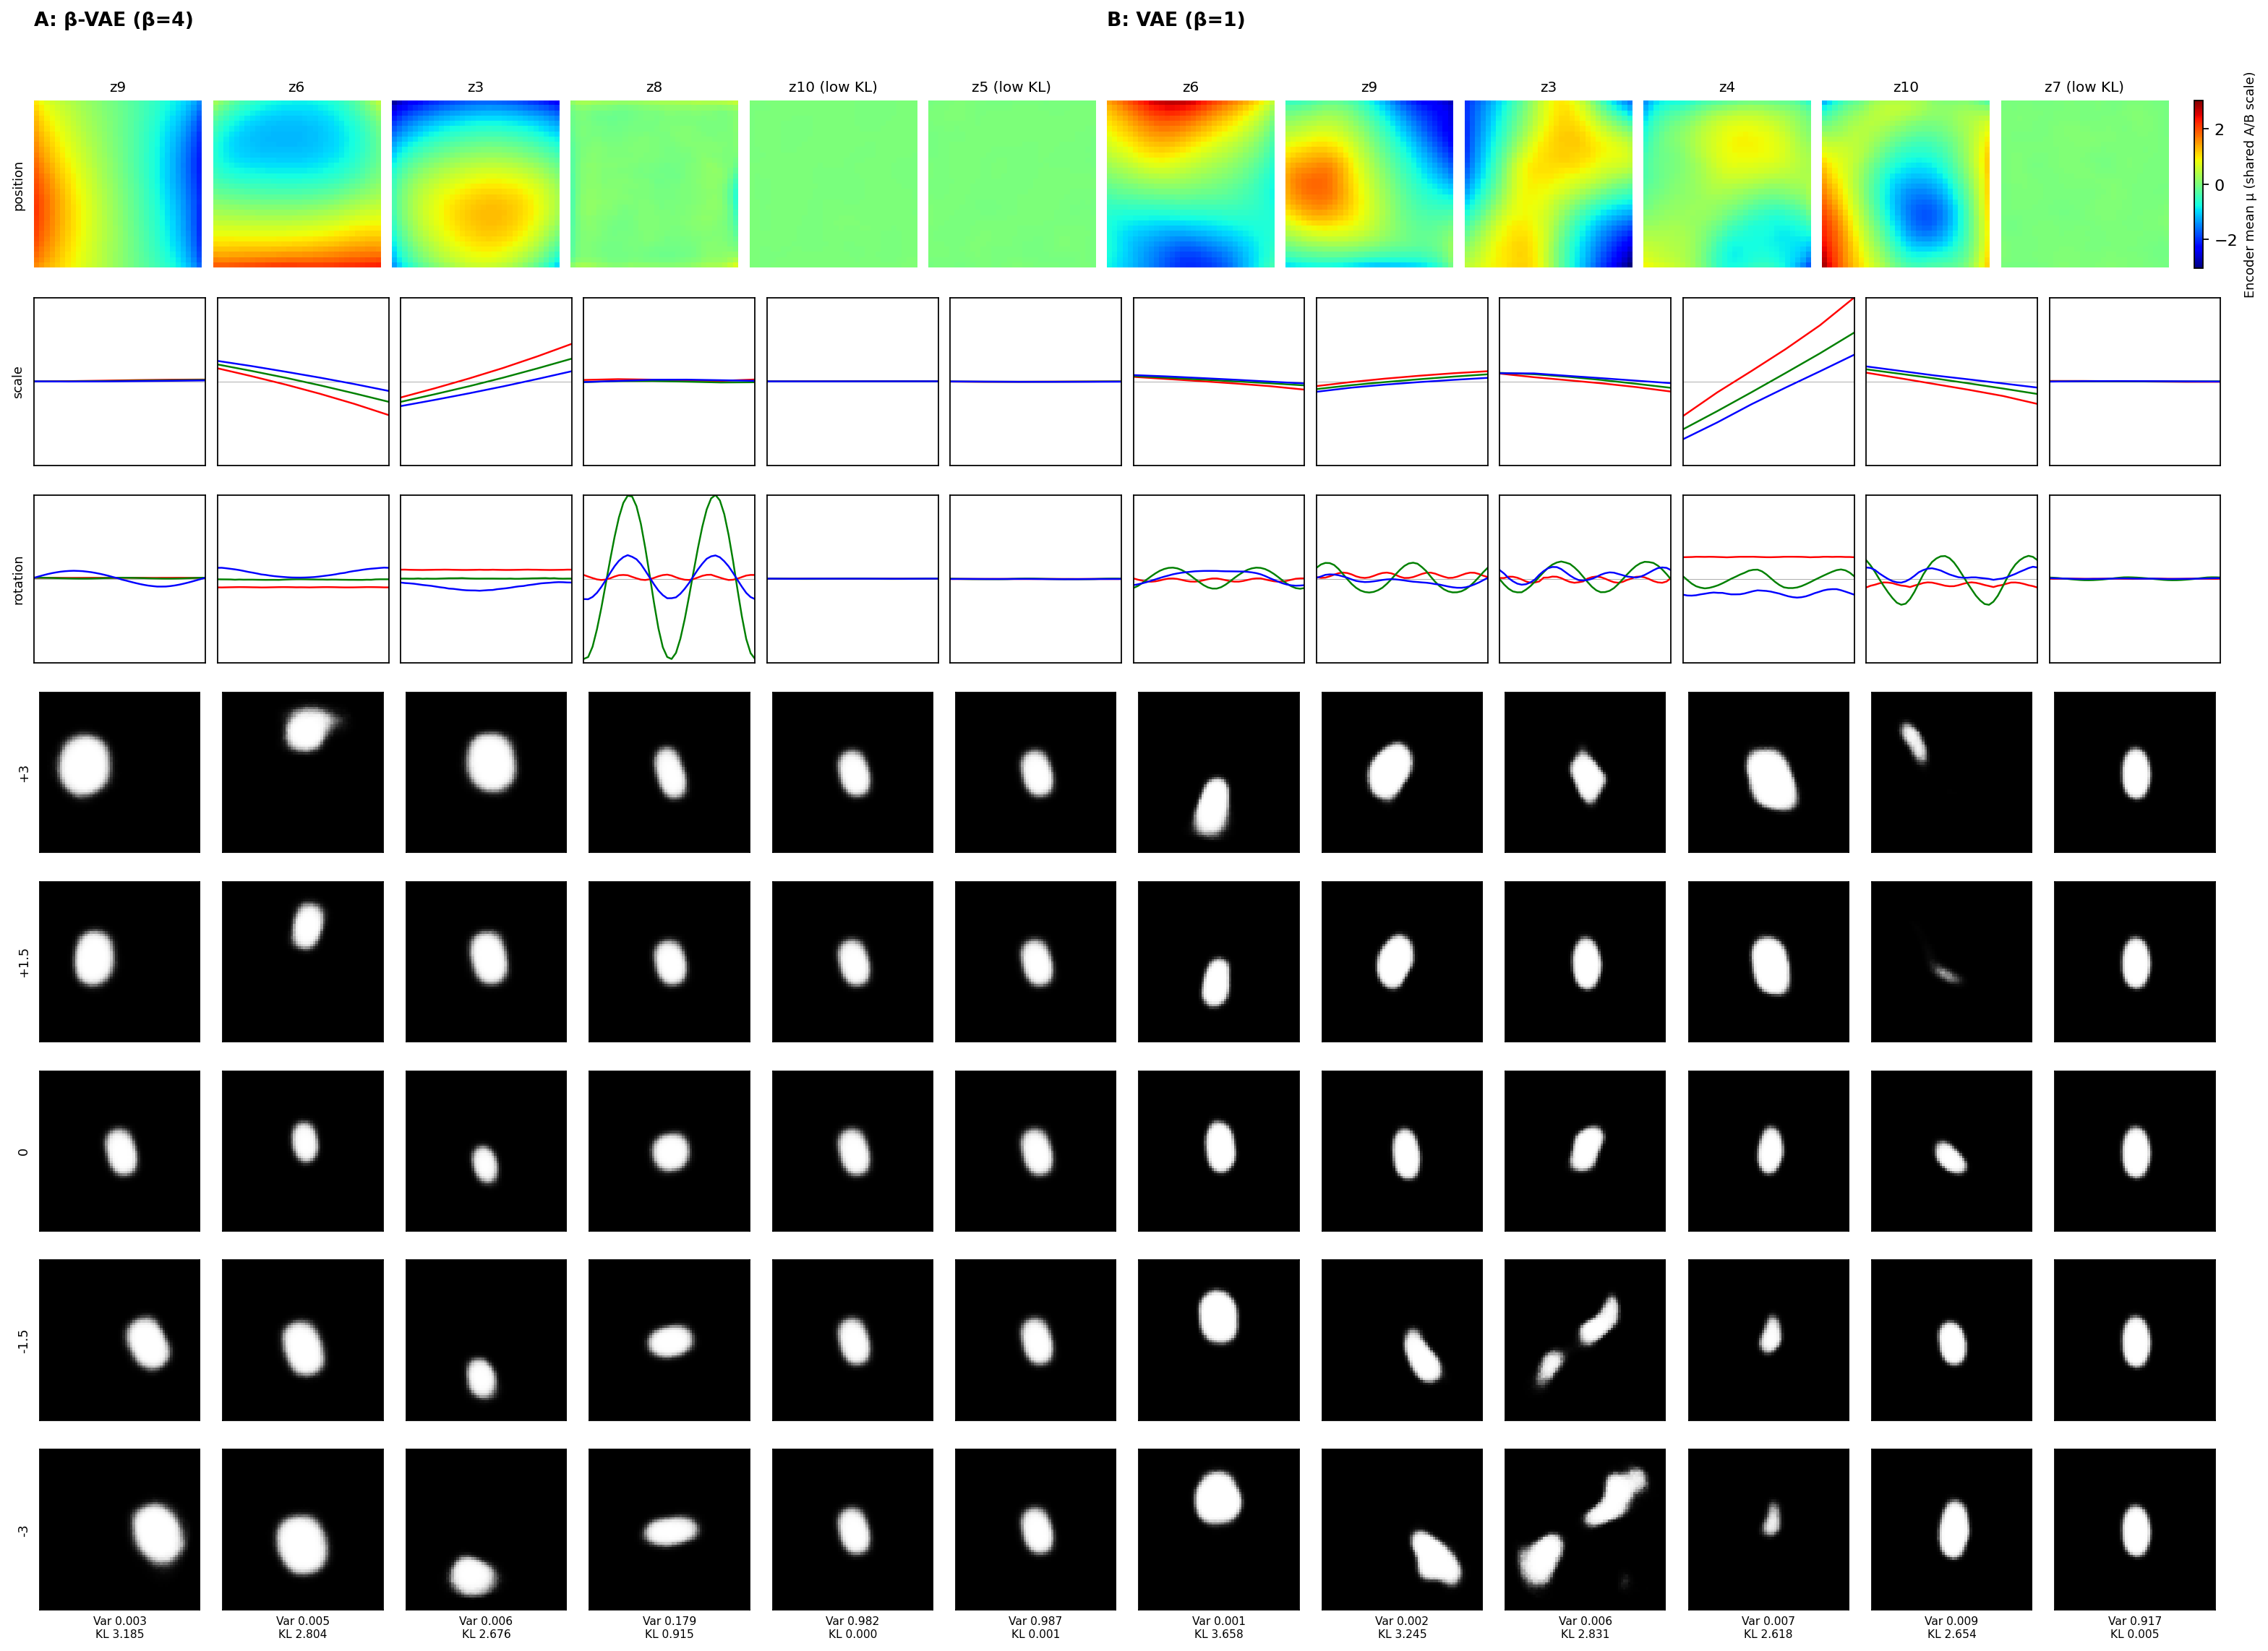


FIGURE 7A: beta=4.0, seed=42, steps=30000
Total KL: 9.5814
Active latents (KL > 0.1): 4
Reconstruction BCE/image: 86.0633
z9: KL=3.185, signals={'position_x': 0.981, 'position_y': 0.014, 'scale': 0.0, 'rotation': 0.005}
z6: KL=2.804, signals={'position_x': 0.039, 'position_y': 0.882, 'scale': 0.077, 'rotation': 0.002}
z3: KL=2.676, signals={'position_x': 0.164, 'position_y': 0.728, 'scale': 0.107, 'rotation': 0.001}
z8: KL=0.915, signals={'position_x': 0.006, 'position_y': 0.007, 'scale': 0.0, 'rotation': 0.987}
z10: KL=0.000, signals={'position_x': 0.295, 'position_y': 0.511, 'scale': 0.045, 'rotation': 0.149}
z5: KL=0.001, signals={'position_x': 0.245, 'position_y': 0.547, 'scale': 0.097, 'rotation': 0.111}

FIGURE 7B: beta=1.0, seed=42, steps=30000
Total KL: 17.3698
Active latents (KL > 0.1): 6
Reconstruction BCE/image: 61.5318
z6: KL=3.658, signals={'position_x': 0.032, 'position_y': 0.95, 'scale': 0.005, 'rotation': 0.013}
z9: KL=3.245, signals={'position_x': 0.656, 'position_y':

In [ ]:

import json
import shutil
import numpy as np
from IPython.display import display, Image

display(Image(filename=str(MATCHED_FIGURES / 'figure7_AB.png')))

with open(MATCHED_FIGURES / 'figure7_metrics.json') as f:
    metrics = json.load(f)

for label in ('A', 'B'):
    m = metrics[label]
    print(f'\nFIGURE 7{label}: beta={m["beta"]}, seed={m["seed"]}, steps={m["steps"]}')

    kl = np.asarray(m['mean_kl_all_10'], dtype=float)
    print('Total KL:', round(float(kl.sum()), 4))
    print('Active latents (KL > 0.1):', int((kl > 0.1).sum()))
    print('Reconstruction BCE/image:',
          round(m['reconstruction']['bce_per_image'], 4))

    fractions = m['factor_response_diagnostics'][
        'within_4_factor_signal_fractions'
    ]

    for latent_id in m['displayed_latent_ids_1_based']:
        j = latent_id - 1
        signals = {
            factor: round(float(values[j]), 3)
            for factor, values in fractions.items()
        }
        print(f'z{latent_id}: KL={kl[j]:.3f}, signals={signals}')

# Save both models and all generated figures to Google Drive.
DEST = DRIVE_BASE / 'paper3_seed_comparison' / 'matched_seed42'
DEST.mkdir(parents=True, exist_ok=True)

for beta in (1, 4):
    source = SECOND / f'beta{beta}'
    target = DEST / f'beta{beta}'
    target.mkdir(parents=True, exist_ok=True)

    for filename in ('model.pt', 'latest.pt', 'history.json'):
        file = source / filename
        if file.is_file():
            shutil.copy2(file, target / filename)

for file in MATCHED_FIGURES.iterdir():
    if file.is_file():
        shutil.copy2(file, DEST / file.name)

print('\nMatched-seed experiment backed up to:', DEST)
